In [1]:
pip install tensorflow numpy matplotlib scikit-learn

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl (351.2 MB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'D:\\anaconda\\Lib\\site-packages\\tensorflow\\lite\\tools\\optimize\\sparsity\\format_converter_wrapper_pybind11.py'
Consider using the `--user` option or check the permissions.



In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

print("Environment Setup Completed!")

TensorFlow Version: 2.21.0
NumPy Version: 2.3.5
Environment Setup Completed!


In [6]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [7]:
# Load MNIST dataset
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
# Display dataset shapes

print("Training Images Shape:", x_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Testing Images Shape:", x_test.shape)
print("Testing Labels Shape:", y_test.shape)

Training Images Shape: (60000, 28, 28)
Training Labels Shape: (60000,)
Testing Images Shape: (10000, 28, 28)
Testing Labels Shape: (10000,)


In [9]:
print("First 10 Labels:", y_train[:10])

print("\nFirst Image Pixel Values:")
print(x_train[0])

print("\nMinimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

First 10 Labels: [5 0 4 1 9 2 1 3 1 4]

First Image Pixel Values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0

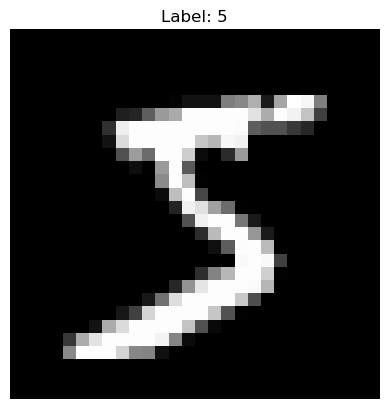

In [10]:
# Display the first image

plt.imshow(x_train[0], cmap='gray')

plt.title(f"Label: {y_train[0]}")
plt.axis('off')

plt.show()

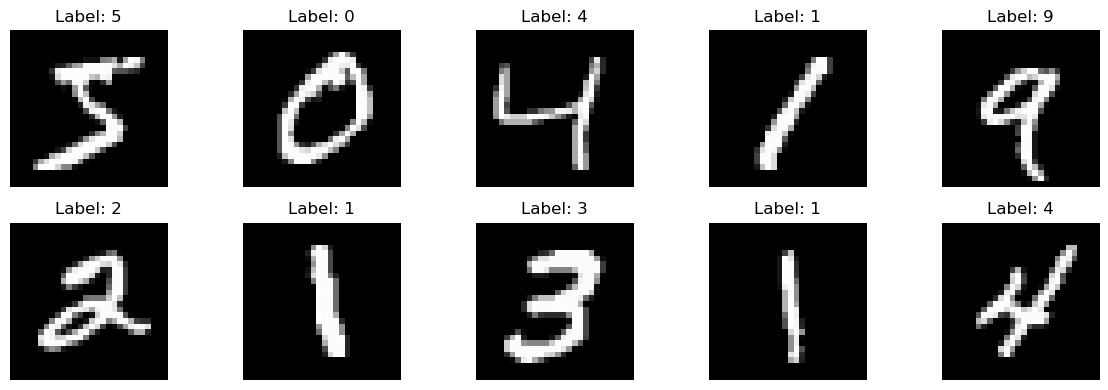

In [11]:
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train[i], cmap='gray')

    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

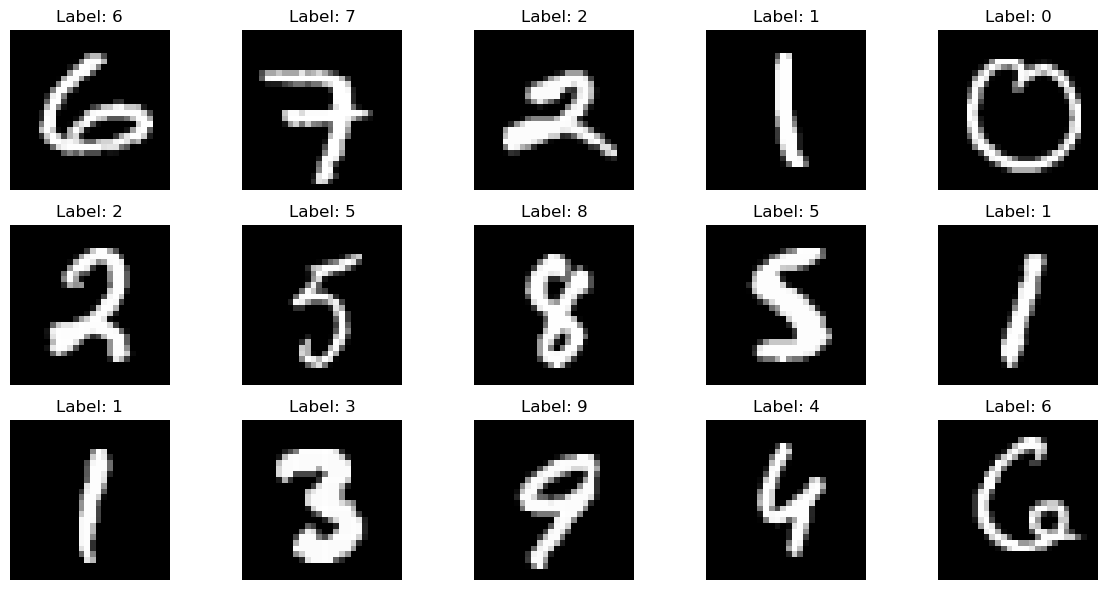

In [12]:
plt.figure(figsize=(12, 6))

for i in range(15):
    index = np.random.randint(0, len(x_train))

    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train[index], cmap='gray')
    plt.title(f"Label: {y_train[index]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# Normalize pixel values

x_train = x_train / 255.0
x_test = x_test / 255.0

print("Normalization completed!")

Normalization completed!


In [14]:
print("Training Data:")
print("Minimum Value:", x_train.min())
print("Maximum Value:", x_train.max())

print("\nTesting Data:")
print("Minimum Value:", x_test.min())
print("Maximum Value:", x_test.max())

Training Data:
Minimum Value: 0.0
Maximum Value: 1.0

Testing Data:
Minimum Value: 0.0
Maximum Value: 1.0


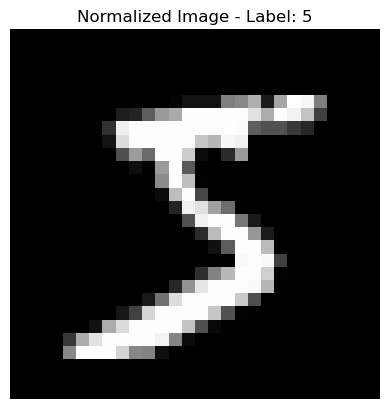

In [15]:
plt.imshow(x_train[0], cmap='gray')

plt.title(f"Normalized Image - Label: {y_train[0]}")
plt.axis('off')

plt.show()

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Build ANN model
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

print("ANN Model Created Successfully!")

D:\anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


ANN Model Created Successfully!


In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Compile the ANN model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [19]:
print("Optimizer:", model.optimizer)
print("Loss Function:", model.loss)
print("Metrics:", model.metrics_names)

Optimizer: <keras.src.optimizers.adam.Adam object at 0x000001735D445550>
Loss Function: sparse_categorical_crossentropy
Metrics: ['loss', 'compile_metrics']


In [20]:
# Train the ANN model

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - accuracy: 0.9258 - loss: 0.2571 - val_accuracy: 0.9683 - val_loss: 0.1082
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9662 - loss: 0.1075 - val_accuracy: 0.9730 - val_loss: 0.0975
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9757 - loss: 0.0760 - val_accuracy: 0.9758 - val_loss: 0.0844
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9824 - loss: 0.0555 - val_accuracy: 0.9790 - val_loss: 0.0724
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9856 - loss: 0.0440 - val_accuracy: 0.9800 - val_loss: 0.0732
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9884 - loss: 0.0365 - val_accuracy: 0.9765 - val_loss: 0.0771
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9904 - loss: 0.0297 - val_accuracy: 0.9827 - val_loss: 0.0728
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9917 - loss: 0

In [21]:
print("Training Accuracy:", history.history['accuracy'][-1])
print("Validation Accuracy:", history.history['val_accuracy'][-1])

print("Training Loss:", history.history['loss'][-1])
print("Validation Loss:", history.history['val_loss'][-1])

Training Accuracy: 0.9933518767356873
Validation Accuracy: 0.9778333306312561
Training Loss: 0.020044274628162384
Validation Loss: 0.08901752531528473


In [22]:
# Evaluate the ANN model

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("\nModel Evaluation Results")
print("------------------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9776 - loss: 0.0892

Model Evaluation Results
------------------------
Test Loss: 0.08916044235229492
Test Accuracy: 97.75999784469604 %


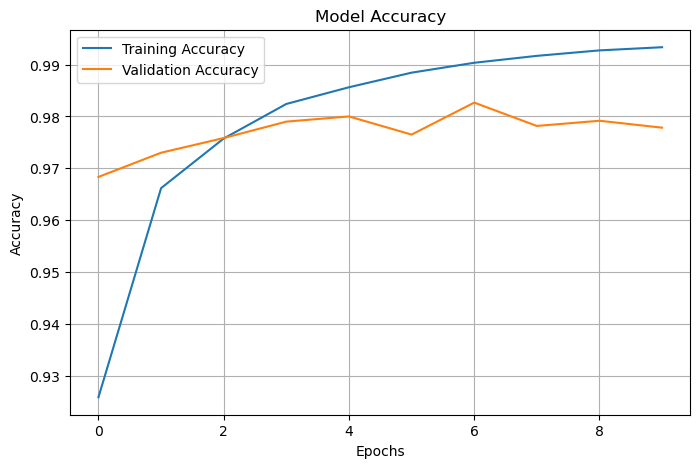

In [23]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

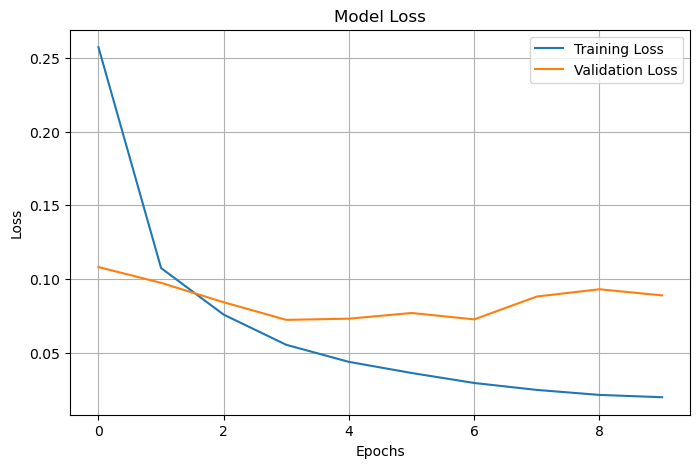

In [24]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [25]:
# Predict testing images

y_pred_prob = model.predict(x_test)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual Labels:   ", y_test[:10])
print("Predicted Labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Actual Labels:    [7 2 1 0 4 1 4 9 5 9]
Predicted Labels: [7 2 1 0 4 1 4 9 5 9]


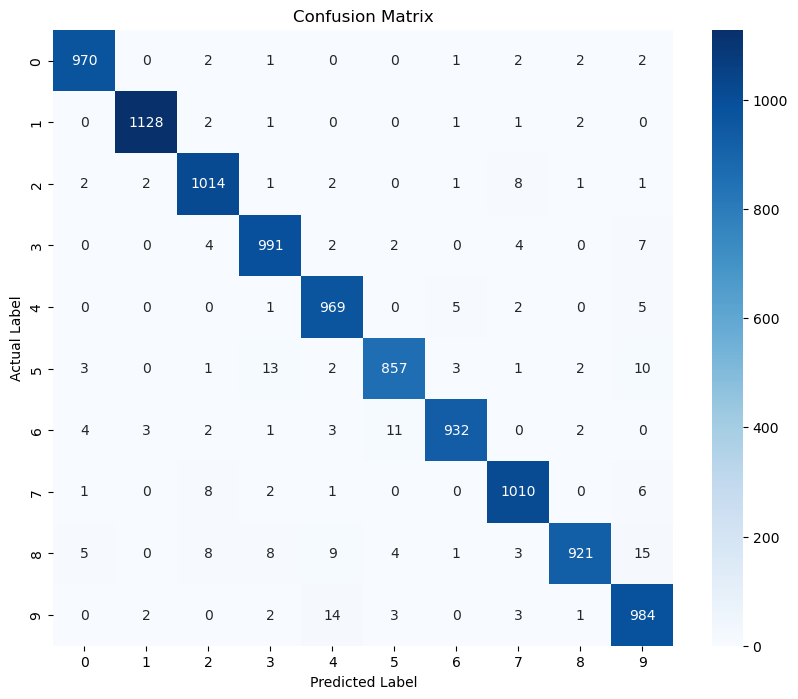

In [26]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [27]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.97      0.99      0.98       982
           5       0.98      0.96      0.97       892
           6       0.99      0.97      0.98       958
           7       0.98      0.98      0.98      1028
           8       0.99      0.95      0.97       974
           9       0.96      0.98      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



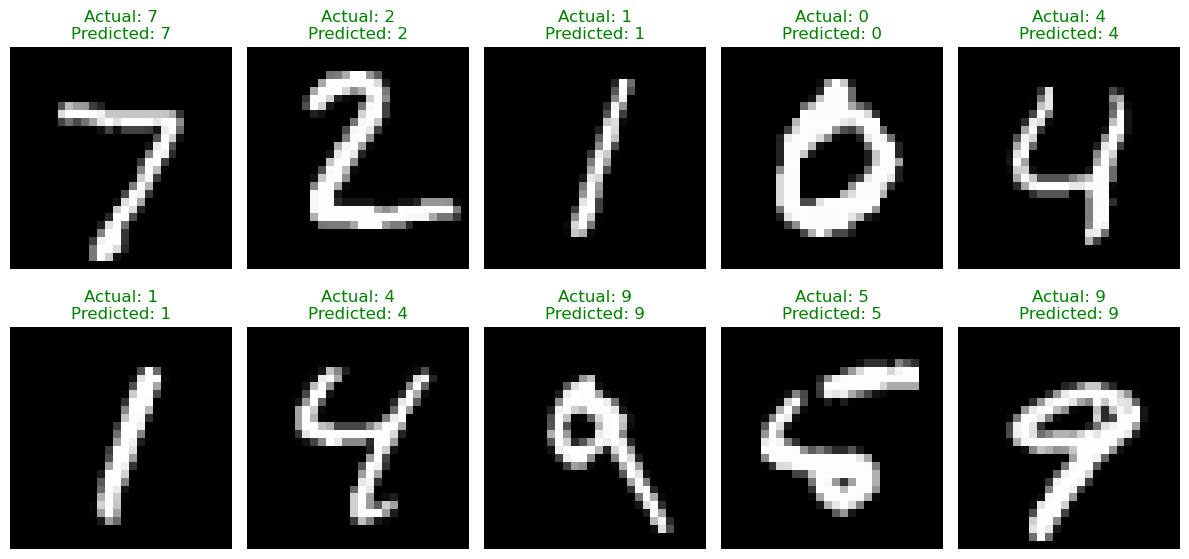

In [28]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    color = 'green' if y_test[i] == y_pred[i] else 'red'

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [31]:
def build_ann():

    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [33]:
experiments = [
    (5, 32),
    (10, 32),
    (10, 64)
]

results = []

for epochs, batch_size in experiments:

    print(f"\nEpochs: {epochs}, Batch Size: {batch_size}")

    temp_model = build_ann()

    temp_model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.1,
        verbose=0
    )

    loss, accuracy = temp_model.evaluate(
        x_test, y_test, verbose=0
    )

    results.append({
        'Epochs': epochs,
        'Batch Size': batch_size,
        'Test Accuracy': accuracy,
        'Test Loss': loss
    })

import pandas as pd

results_df = pd.DataFrame(results)
print(results_df)


Epochs: 5, Batch Size: 32

Epochs: 10, Batch Size: 32

Epochs: 10, Batch Size: 64
   Epochs  Batch Size  Test Accuracy  Test Loss
0       5          32         0.9759   0.088716
1      10          32         0.9738   0.114584
2      10          64         0.9784   0.083205


In [34]:
model.save("mnist_ann_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [35]:
from tensorflow.keras.models import load_model

loaded_model = load_model("mnist_ann_model.keras")

print("Saved ANN model loaded successfully!")

Saved ANN model loaded successfully!


In [36]:
# Select an image
index = 25

# Get the image
sample_image = x_test[index]

# Predict the digit
prediction = loaded_model.predict(
    sample_image.reshape(1, 28, 28),
    verbose=0
)

predicted_digit = np.argmax(prediction)

print("Actual Digit:", y_test[index])
print("Predicted Digit:", predicted_digit)

Actual Digit: 0
Predicted Digit: 0


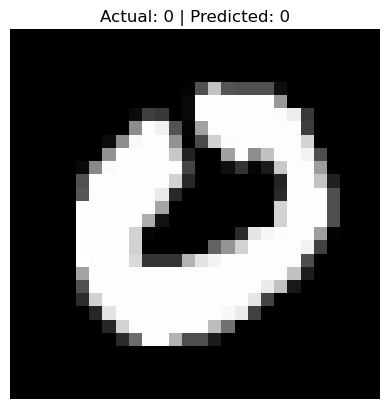

In [37]:
plt.imshow(sample_image, cmap='gray')

plt.title(
    f"Actual: {y_test[index]} | Predicted: {predicted_digit}"
)

plt.axis('off')
plt.show()

In [38]:
confidence = np.max(prediction) * 100

print("Predicted Digit:", predicted_digit)
print("Prediction Confidence:", round(confidence, 2), "%")

Predicted Digit: 0
Prediction Confidence: 100.0 %


In [40]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

In [41]:
pip install pillow

Note: you may need to restart the kernel to use updated packages.


In [42]:
def preprocess_image(image_path):

    # Open image and convert to grayscale
    img = Image.open(image_path).convert('L')

    # Invert colors
    img = ImageOps.invert(img)

    # Improve contrast
    img = ImageOps.autocontrast(img)

    # Find digit boundaries
    img = img.point(lambda p: 255 if p > 40 else 0)

    bbox = img.getbbox()

    if bbox is None:
        raise ValueError("No handwritten digit detected.")

    img = img.crop(bbox)

    # Resize while maintaining aspect ratio
    img.thumbnail((20, 20))

    # Create a 28x28 black canvas
    canvas = Image.new('L', (28, 28), 0)

    # Center the digit
    x = (28 - img.width) // 2
    y = (28 - img.height) // 2

    canvas.paste(img, (x, y))

    # Normalize pixel values
    image_array = np.array(canvas) / 255.0

    return image_array

In [47]:
image_path = r"C:\Users\Chaithanya Reddy\Projects\Handwritten_Digit_Recognition\ex.jpg"

processed_image = preprocess_image(image_path)

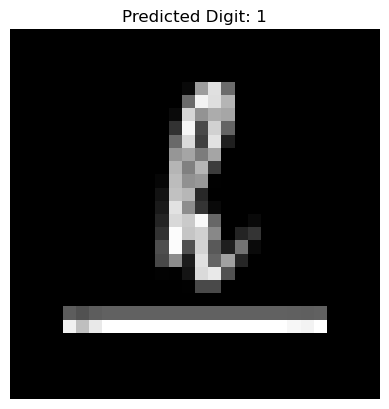

Predicted Digit: 1
Confidence: 99.47 %


In [48]:
# Load saved model
loaded_model = load_model("mnist_ann_model.keras")

# Make prediction
prediction = loaded_model.predict(
    processed_image.reshape(1, 28, 28),
    verbose=0
)

predicted_digit = np.argmax(prediction)
confidence = np.max(prediction) * 100

# Display processed image
plt.imshow(processed_image, cmap='gray')
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis('off')
plt.show()

print("Predicted Digit:", predicted_digit)
print("Confidence:", round(confidence, 2), "%")

In [49]:
temp_model.save("mnist_ann_model_best.keras")

print("Best ANN model saved successfully!")

Best ANN model saved successfully!


# Conclusion

The Handwritten Digit Recognition project was successfully implemented using an Artificial Neural Network (ANN) with TensorFlow and Keras.

The MNIST dataset containing 70,000 grayscale handwritten digit images was used for training and testing. Data preprocessing was performed by normalizing pixel values between 0 and 1.

The ANN model was developed using Flatten and Dense layers with ReLU and Softmax activation functions. The model was compiled using the Adam optimizer and Sparse Categorical Crossentropy loss function.

Different training configurations were experimented with, and the best configuration achieved **97.84% test accuracy** with 10 epochs and a batch size of 64.

Model performance was evaluated using accuracy, loss, confusion matrix, precision, recall and F1-score.

The project demonstrates how Artificial Neural Networks can learn handwritten digit patterns and classify images into numerical digits from 0 to 9.